# Quantum Computing Laboratory Activity 4
## An Introduction to Quantum Machine Learning

This lab builds on everything so far: Lab 1's single-qubit gates, Lab 2's multi-qubit circuits
and entanglement, and Lab 3's encounter with real, imperfect hardware. Here we put all of it to a
new use — **Quantum Machine Learning (QML)**: using parameterized quantum circuits as trainable
models, the same way a neural network's weights are trainable, to learn from classical data.

By the end of this notebook you will be able to:
- Explain the general QML workflow and where each Lab 1–3 concept fits into it
- Encode classical data into a quantum state using a **feature map**
- Build a trainable quantum circuit — an **ansatz** — and explain what makes it "trainable"
- Explain the **hybrid quantum-classical training loop** that a `VQC` runs under the hood
- Train a **Variational Quantum Classifier** on a real dataset and evaluate its accuracy
- Recognize when a QML model is struggling, and connect that back to feature choice — not just
  "more qubits"

$\newcommand{\bra}[1]{\langle#1|}$
$\newcommand{\ket}[1]{|#1\rangle}$

## Setup

In [1]:
# Same dependency-trap note as Labs 1-3: pin numpy/contourpy/matplotlib together so
# qiskit's numpy>=2.0 requirement doesn't get silently downgraded by another package.
# scikit-learn and the QML packages are added fresh here.
!pip install -U "numpy>=2.0,<2.8" "contourpy>=1.3" "matplotlib>=3.9" qiskit qiskit-aer pylatexenc charset_normalizer
!pip install -U scikit-learn threadpoolctl joblib narwhals qiskit-machine-learning qiskit-algorithms

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 2.4 MB/s  0:00:032.4 MB/s eta 0:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 2.3 MB/s  0:00:00m 2.4 MB/s eta 0:00:01
  Attempting uninstall: qiskit
    Found existing installation: qiskit 2.6.0
    Uninstalling qiskit-2.6.0:
      Successfully uninstalled qiskit-2.6.0
  Attempting uninstall: qiskit-aer━━━━━━━━━━━━━━━━━━━━ 0/2 [qiskit]
    Found existing installation: qiskit-aer 0.17.2 0/2 [qiskit]
    Uninstalling qiskit-aer-0.17.2:━━━━━━━━━━━━━━━ 0/2 [qiskit]
      Successfully uninstalled qiskit-aer-0.17.2━━ 0/2 [qiskit]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [qiskit-aer] 1/2 [qiskit-aer]

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 907.1 kB/s  0:00:09896.5 kB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 876.3/876.3 kB 711.1 kB/s  0:00:01.8 kB/s eta 0:00:01
   ━━━━━━━━

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score
from sklearn.feature_extraction.text import CountVectorizer

from qiskit import QuantumCircuit
from qiskit.circuit.library import zz_feature_map, real_amplitudes
from qiskit.visualization import plot_histogram
from qiskit_algorithms.optimizers import COBYLA
from qiskit_algorithms.utils import algorithm_globals
from qiskit_machine_learning.algorithms.classifiers import VQC

algorithm_globals.random_seed = 42
np.random.seed(42)

## 1. What Is Quantum Machine Learning?

Classical machine learning learns a function from data: given examples $(x, y)$, find parameters
$\theta$ so a model $f_\theta(x)$ predicts $y$ well. A neural network's $\theta$ are its weights.

**Quantum machine learning does the same thing, with one swap**: $f_\theta$ becomes a
**parameterized quantum circuit**, and $\theta$ becomes the circuit's **gate angles** — the same
kind of parameter you've been passing to `ry(angle, qubit)` since Lab 2. Training still means
"adjust the parameters to reduce error," exactly like training a neural network — the difference
is *what kind of function* $f_\theta$ computes.

The general QML workflow:

$$\text{Dataset} \;\to\; \text{Normalize} \;\to\; \text{Encode into a quantum state (feature map)}
\;\to\; \text{Trainable circuit (ansatz)} \;\to\; \text{Measure} \;\to\; \text{Prediction}$$

Two new pieces to learn in this lab — the **feature map** (how classical numbers become a quantum
state) and the **ansatz** (the trainable part) — everything else (circuits, gates, measurement,
simulation) is exactly what you already know from Labs 1–3.

## 2. Encoding Classical Data: Feature Maps

A **feature map** takes a classical data point — a list of numbers — and turns it into a quantum
state, by using those numbers as **rotation angles**. Qiskit's `zz_feature_map` is a standard
choice: it applies an $H$ to every qubit (superposition, Lab 1), a $Z$-rotation per feature
(angle = that feature's value), and then entangling $ZZ$ interactions between every pair of qubits
(Lab 2) so the encoding captures not just individual feature values but how features relate to
each other.

Let's build one for 2 features (2 qubits) and look at it directly:

Qubits: 2   Parameters: 2


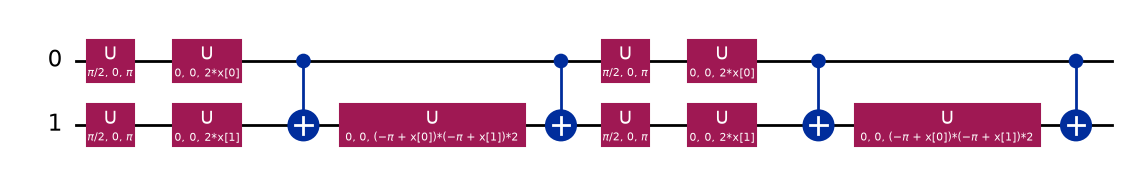

In [3]:
feature_map = zz_feature_map(feature_dimension=2, reps=2)
print(f"Qubits: {feature_map.num_qubits}   Parameters: {feature_map.num_parameters}")
feature_map.decompose().draw('mpl')

`reps=2` means the encode-then-entangle block repeats twice — more repetitions can capture
more complex relationships between features, at the cost of a deeper (and on real hardware,
noisier — Lab 3 §4) circuit.

**A critical, easy-to-miss detail: the scale of your data matters.** These are *rotation* angles —
if every feature is squeezed into a tiny range, every encoded state ends up nearly identical
(barely rotated away from $|0\rangle$), and the classifier has almost nothing to distinguish.
`MinMaxScaler` (which you've used in earlier labs to get data into $[0,1]$) still works, but for
angle encoding specifically, a wider spread helps the circuit actually tell data points apart.

## 3. Variational Circuits: The Ansatz

The feature map encodes *data*. The **ansatz** is a *separate* circuit, appended right after it,
whose rotation angles are **trainable parameters** — not data, but the quantum equivalent of a
neural network's weights. Qiskit's `real_amplitudes` is a standard choice: layers of `ry` rotations
(trainable) alternating with `cx` entangling gates (fixed), repeated `reps` times.

Qubits: 3   Trainable parameters: 12


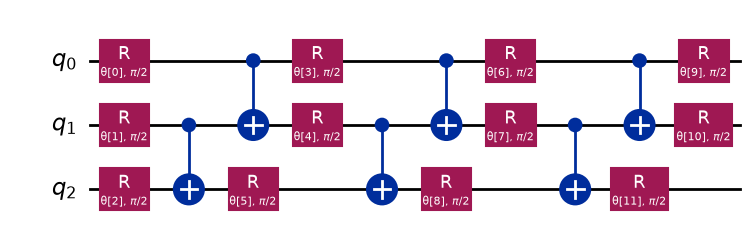

In [22]:
ansatz = real_amplitudes(num_qubits=3, reps=3)
print(f"Qubits: {ansatz.num_qubits}   Trainable parameters: {ansatz.num_parameters}")
ansatz.decompose().draw('mpl')

Those 6 angles (printed above as `Trainable parameters`) are exactly what "training" will adjust. Put feature map and
ansatz back to back, measure, and you have a complete trainable quantum model — the input data sets
the feature-map angles, training sets the ansatz angles, and the measurement outcome becomes the
prediction.

## 4. The Hybrid Training Loop

Here's the part that makes this "hybrid quantum-classical": the quantum circuit computes a
prediction, but **a classical optimizer** (`COBYLA`, which you don't need to understand the inner
workings of — treat it like `scipy.optimize`) decides how to adjust the ansatz's parameters to
reduce error, the same iterative "try, measure error, adjust" loop as training any other ML model.
Qiskit's `VQC` (**Variational Quantum Classifier**) wraps this entire loop — feature map, ansatz,
optimizer, and the repeated run-measure-adjust cycle — behind a familiar `.fit(X, y)` /
`.predict(X)` interface, just like a scikit-learn classifier.

Let's see the whole pipeline end to end on a tiny synthetic dataset first, before using a real one,
so the mechanics are clear without a real dataset's complications:

In [23]:
# A simple synthetic 2-feature dataset: label = 1 if the two features sum past 1, else 0
X_toy = np.random.rand(30, 2)
y_toy = (X_toy[:, 0] + X_toy[:, 1] > 1).astype(int)

X_train, X_test, y_train, y_test = train_test_split(X_toy, y_toy, test_size=0.25, random_state=42)

toy_feature_map = zz_feature_map(feature_dimension=2, reps=4)
toy_ansatz = real_amplitudes(num_qubits=2, reps=4)
toy_optimizer = COBYLA(maxiter=50)

vqc_toy = VQC(feature_map=toy_feature_map, ansatz=toy_ansatz, optimizer=toy_optimizer)
vqc_toy.fit(X_train, y_train)

toy_preds = vqc_toy.predict(X_test)
print("Predictions:", toy_preds)
print("Actual:     ", y_test)
print("Accuracy:   ", accuracy_score(y_test, toy_preds))

Predictions: [1 0 0 1 0 0 0 1]
Actual:      [1 0 1 1 0 0 0 0]
Accuracy:    0.75


That's the entire loop: `.fit()` ran the hybrid training (many rounds of: run the circuit on
every training point with the current ansatz parameters, compute how wrong the predictions were,
let `COBYLA` propose new parameters, repeat), and `.predict()` ran the trained circuit on new data.
Everything from here is this exact same pattern, applied to a real dataset.

**Try It Yourself — Exercise 1.** Rebuild `vqc_toy` with `reps=2` for both the feature map and the
ansatz instead of `reps=1`, keeping everything else the same. Does accuracy change? Does training
take noticeably longer (wrap the `.fit()` call with Python's `time.time()` to check)?

In [6]:
# Write your solution below




## 5. From Text to Quantum: Encoding Non-Numeric Data

Quantum circuits only understand numbers. If your data is text — like classifying a message as
spam or not — you need a classical feature-extraction step *first*, exactly as you would for any
other ML model. `CountVectorizer` is a standard, simple choice: it counts how often each of a
chosen set of words appears in each message, turning text into a numeric vector.

In [26]:
messages = [
    "win money now", "claim your free prize", "meeting at 3pm", "project discussion tomorrow",
    "limited time offer now", "lunch schedule today", "congratulations you won free", "submit your assignment",
    "free cash prize winner", "team sync this afternoon", "urgent claim reward now", "homework due friday",
    "you have won a free prize", "quarterly report meeting", "click to claim your money", "office party schedule",
]
labels = np.array([1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0])  # 1 = spam, 0 = not spam


In [33]:
vectorizer = CountVectorizer(max_features=5)
X_spam = vectorizer.fit_transform(messages).toarray().astype(float)
vectorizer.get_feature_names_out()

array(['claim', 'free', 'now', 'prize', 'your'], dtype=object)

In [29]:
print("Vocabulary chosen:", vectorizer.get_feature_names_out())
print(X_spam)

Vocabulary chosen: ['claim' 'free' 'now' 'prize' 'your']
[[0. 0. 1. 0. 0.]
 [1. 1. 0. 1. 1.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 1.]
 [0. 1. 0. 1. 0.]
 [0. 0. 0. 0. 0.]
 [1. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 1. 0. 1. 0.]
 [0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0.]]


Each message is now a 4-number vector — count of each chosen word — ready for exactly the
same pipeline as any numeric dataset. From here it's identical to Section 4:

In [8]:
scaler = MinMaxScaler()
X_spam_scaled = scaler.fit_transform(X_spam)

X_train, X_test, y_train, y_test = train_test_split(
    X_spam_scaled, labels, test_size=0.25, random_state=42, stratify=labels)

spam_feature_map = zz_feature_map(feature_dimension=4, reps=2)
spam_ansatz = real_amplitudes(num_qubits=4, reps=2)
spam_optimizer = COBYLA(maxiter=80)

vqc_spam = VQC(feature_map=spam_feature_map, ansatz=spam_ansatz, optimizer=spam_optimizer)
vqc_spam.fit(X_train, y_train)

spam_preds = vqc_spam.predict(X_test)
print("Predictions:", spam_preds)
print("Actual:     ", y_test)
print("Accuracy:   ", accuracy_score(y_test, spam_preds))

Predictions: [1 0 0 1]
Actual:      [0 1 0 1]
Accuracy:    0.5


With only 16 tiny messages and a 4-word vocabulary this is a toy example, not a real spam
filter — but the pipeline is identical to what a real one would use. The lesson here isn't "4
qubits beat 2" — it's that **feature engineering (which words you pick, how many messages you
have) matters as much to a quantum model as to a classical one.** A quantum circuit doesn't rescue
a weak feature set.

## 6. Guided Lab: Classifying Iris Flowers

Now a real, well-known dataset. The Iris dataset has 3 species (setosa, versicolor, virginica) and
4 measurements per flower (sepal length/width, petal length/width). We'll start with the classic
easy case — **setosa vs. versicolor**, which even a simple classical linear model separates
perfectly — to confirm our pipeline works, before the harder case becomes the Student Task below.

### Step 1 — Load and inspect

In [34]:
iris = load_iris()
X_all, y_all = iris.data, iris.target
print("Full dataset:", X_all.shape, "features:", iris.feature_names)
print("Classes:", list(iris.target_names))

# setosa (0) and versicolor (1) are the first 100 rows
mask = y_all != 2
X_binary, y_binary = X_all[mask], y_all[mask]
print("\nBinary subset (setosa vs. versicolor):", X_binary.shape)

Full dataset: (150, 4) features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]

Binary subset (setosa vs. versicolor): (100, 4)


### Step 2 — Pick features, and *why just two*

All 4 features would mean a 4-qubit circuit — not wrong, but slower to train, and (Section 2's
warning) more features isn't automatically better if they're redundant. Petal length and petal
width are, by a wide margin, the two most discriminative measurements for this species pair — so
we'll use just those two, giving us a fast 2-qubit model *and* a feature space simple enough to
actually plot.

Selected features: petal length (cm) & petal width (cm)


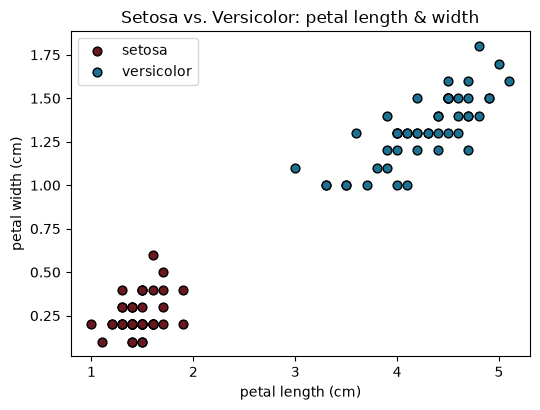

In [35]:
X_2feat = X_binary[:, 2:4]  # petal length, petal width
print("Selected features:", iris.feature_names[2], "&", iris.feature_names[3])

fig, ax = plt.subplots(figsize=(5.5, 4.2))
for cls, color, name in [(0, '#6A171F', 'setosa'), (1, '#1C7293', 'versicolor')]:
    pts = X_2feat[y_binary == cls]
    ax.scatter(pts[:, 0], pts[:, 1], color=color, label=name, edgecolor='k', s=40)
ax.set_xlabel(iris.feature_names[2])
ax.set_ylabel(iris.feature_names[3])
ax.legend()
ax.set_title('Setosa vs. Versicolor: petal length & width')
plt.tight_layout()
plt.show()

### Step 3 — Normalize and split

In [11]:
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X_2feat)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_binary, test_size=0.2, random_state=42, stratify=y_binary)

print("Training:", X_train.shape, " Testing:", X_test.shape)

Training: (80, 2)  Testing: (20, 2)


### Step 4 — Build and train the VQC

In [12]:
iris_feature_map = zz_feature_map(feature_dimension=2, reps=2)
iris_ansatz = real_amplitudes(num_qubits=2, reps=2)
iris_optimizer = COBYLA(maxiter=60)

vqc_iris = VQC(feature_map=iris_feature_map, ansatz=iris_ansatz, optimizer=iris_optimizer)
vqc_iris.fit(X_train, y_train)
print("Training complete.")

Training complete.


### Step 5 — Predict and evaluate

In [13]:
iris_preds = vqc_iris.predict(X_test)

print("Predictions:", iris_preds)
print("Actual:     ", y_test)
print("Accuracy:   ", accuracy_score(y_test, iris_preds))

Predictions: [1 1 1 1 0 0 0 1 0 0 0 1 0 0 0 1 1 0 1 1]
Actual:      [1 1 1 1 0 0 0 1 0 0 0 1 0 0 0 1 1 0 1 1]
Accuracy:    1.0


### Step 6 — See what the model got right (and wrong)

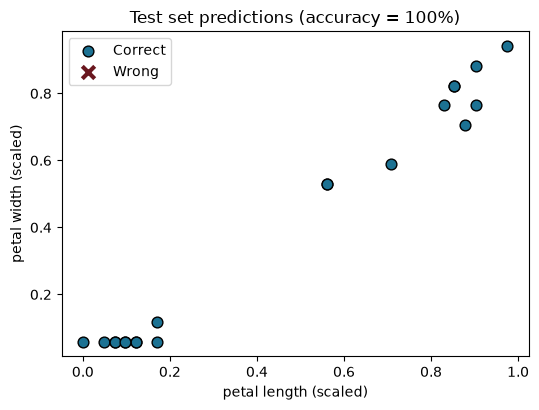

In [14]:
fig, ax = plt.subplots(figsize=(5.5, 4.2))
correct = iris_preds == y_test
ax.scatter(X_test[correct, 0], X_test[correct, 1], color='#1C7293', marker='o',
           s=60, label='Correct', edgecolor='k')
ax.scatter(X_test[~correct, 0], X_test[~correct, 1], color='#6A171F', marker='x',
           s=80, label='Wrong', linewidths=3)
ax.set_xlabel('petal length (scaled)')
ax.set_ylabel('petal width (scaled)')
ax.legend()
ax.set_title(f'Test set predictions (accuracy = {accuracy_score(y_test, iris_preds):.0%})')
plt.tight_layout()
plt.show()

Setosa and versicolor are **linearly separable** — a straight line in this 2D feature space
cleanly divides them — which is exactly why both classical models and this small VQC handle the
pair so well. That's about to change.

## 🧩 Student Task: Versicolor vs. Virginica

### 🎯 Objective

Section 6 worked beautifully because setosa and versicolor are easy to tell apart. **Versicolor
and virginica are not** — their petal measurements overlap, so no straight line separates them
perfectly. Your task is to run the exact same pipeline on this harder pair and see how the model's
behavior changes.

### 🧩 Task 1 — Build the harder dataset

Adapt Section 6 Step 1: instead of excluding virginica (class 2), exclude **setosa** (class 0) this
time, keeping versicolor (1) and virginica (2).

In [15]:
# Write your solution below




### 🧩 Task 2 — Plot it

Adapt Step 2's scatter plot for this new pair (same two features: petal length & width). Before
running any model: just by looking at the plot, do you expect this to be as easy as Section 6?

In [16]:
# Write your solution below




### 🧩 Task 3 — Scale, split, train, evaluate

Adapt Steps 3–5: `MinMaxScaler` → `train_test_split` → build a **fresh** `VQC` (reuse the same
`reps`/`maxiter` as Section 6 first, so the comparison is fair) → `.fit()` → `.predict()` →
`accuracy_score`.

In [17]:
# Write your solution below




### 🧩 Task 4 — Visualize right vs. wrong

Adapt Step 6's correct/wrong scatter plot for your results. Do the *wrong* predictions cluster
somewhere specific on the plot, or are they scattered randomly? What does that pattern (or lack of
one) tell you about where the two species' petal measurements genuinely overlap?

In [18]:
# Write your solution below




### 🧩 Task 5 — Try to close the gap

Pick **one** change and see if it improves accuracy: more `reps` on the ansatz, a higher
`maxiter` on `COBYLA`, or using all 4 features instead of 2 (remember: Section 5's lesson — more
features isn't automatically better, so this is a genuine experiment, not a guaranteed win).
Report what you tried and whether it helped.

In [19]:
# Write your solution below




### Reflection

In 3–4 sentences: why does the *same* model architecture (same feature map, same ansatz, same
optimizer) perform so differently on these two species pairs? What does that tell you about the
role of the **data** versus the role of the **quantum circuit** in how well a QML model performs?

*(Write your answer here.)*